# 02 · Ingeniería de variables y separabilidad
Preguntas: (1) ¿cuánto separa cada variable a las clases? (2) ¿las features nuevas aportan?
(3) ¿qué tan separables son las clases con todas las variables a la vez?

In [1]:
import sys
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from scipy.stats import ks_2samp
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features.features import ID, TARGET, prepare  # noqa: E402

train = pd.read_csv(ROOT / "data/raw/train.csv")
y = train[TARGET].astype(int)
RAW = [c for c in train.columns if c not in (TARGET, ID)]
X_raw = train[RAW]
X_fe = prepare(train)
print("variables crudas:", X_raw.shape[1], "| con features:", X_fe.shape[1])

variables crudas: 10 | con features: 28


## 1. Separabilidad univariada
AUC de cada variable sola (solo filas con valor), Gini = |2·AUC − 1| y estadístico KS entre clases.

,feature,auc,gini_abs,ks,cobertura,nueva
0,util_clip,0.7779,0.5558,0.4612,1.0000,True
1,RevolvingUtilizationOfUnsecuredLines,0.7779,0.5558,0.4612,1.0000,False
2,total_late,0.7708,0.5416,0.4977,0.9981,True
3,late_severity,0.7693,0.5387,0.4872,1.0000,True
4,max_late,0.7661,0.5323,0.4977,0.9981,True
5,late_x_util,0.7644,0.5288,0.4825,1.0000,True
6,age_x_util,0.7564,0.5129,0.4440,1.0000,True
7,any_late,0.7436,0.4872,0.4872,1.0000,True
8,NumberOfTime30-59DaysPastDueNotWorse,0.6822,0.3644,0.3485,0.9981,False
9,NumberOfTimes90DaysLate,0.6521,0.3043,0.3018,0.9981,False


<Axes: title={'center': 'Separabilidad univariada (|Gini|), top 20'}, ylabel='feature'>

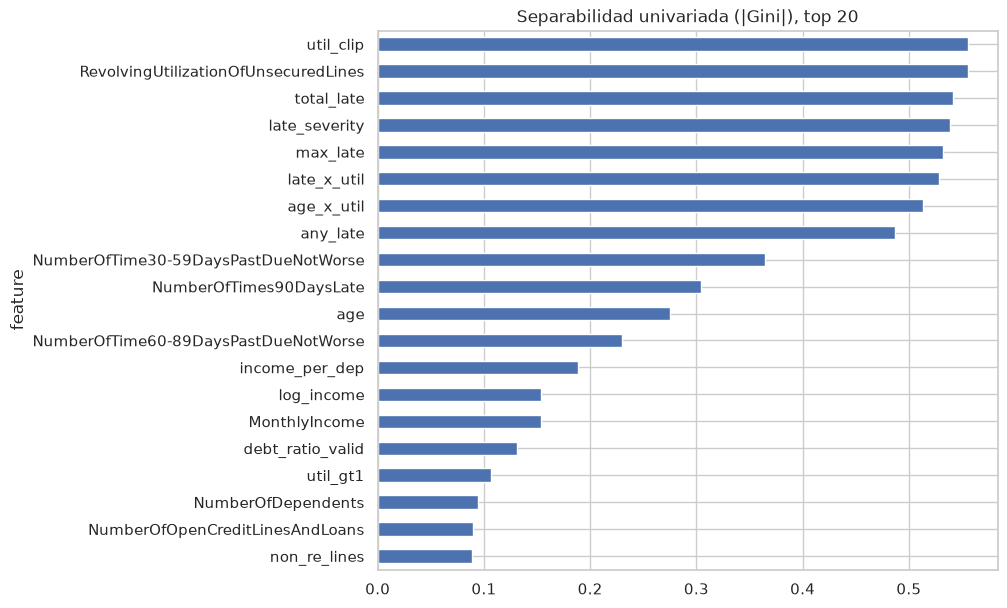

In [2]:
rows = []
for c in X_fe.columns:
    x = X_fe[c]
    m = x.notna()
    if m.sum() < 100 or x[m].nunique() < 2:
        continue
    auc = roc_auc_score(y[m], x[m])
    ks = ks_2samp(x[m & (y == 1)], x[m & (y == 0)]).statistic
    rows.append((c, auc, abs(2 * auc - 1), ks, m.mean()))
sep = (pd.DataFrame(rows, columns=["feature", "auc", "gini_abs", "ks", "cobertura"])
       .sort_values("gini_abs", ascending=False).reset_index(drop=True))
sep["nueva"] = ~sep["feature"].isin(RAW)
display(sep.round(4))
sep.head(20).iloc[::-1].plot.barh(x="feature", y="gini_abs", figsize=(8, 7), legend=False,
                                  title="Separabilidad univariada (|Gini|), top 20")

## 2. Distribuciones por clase de las mejores variables continuas

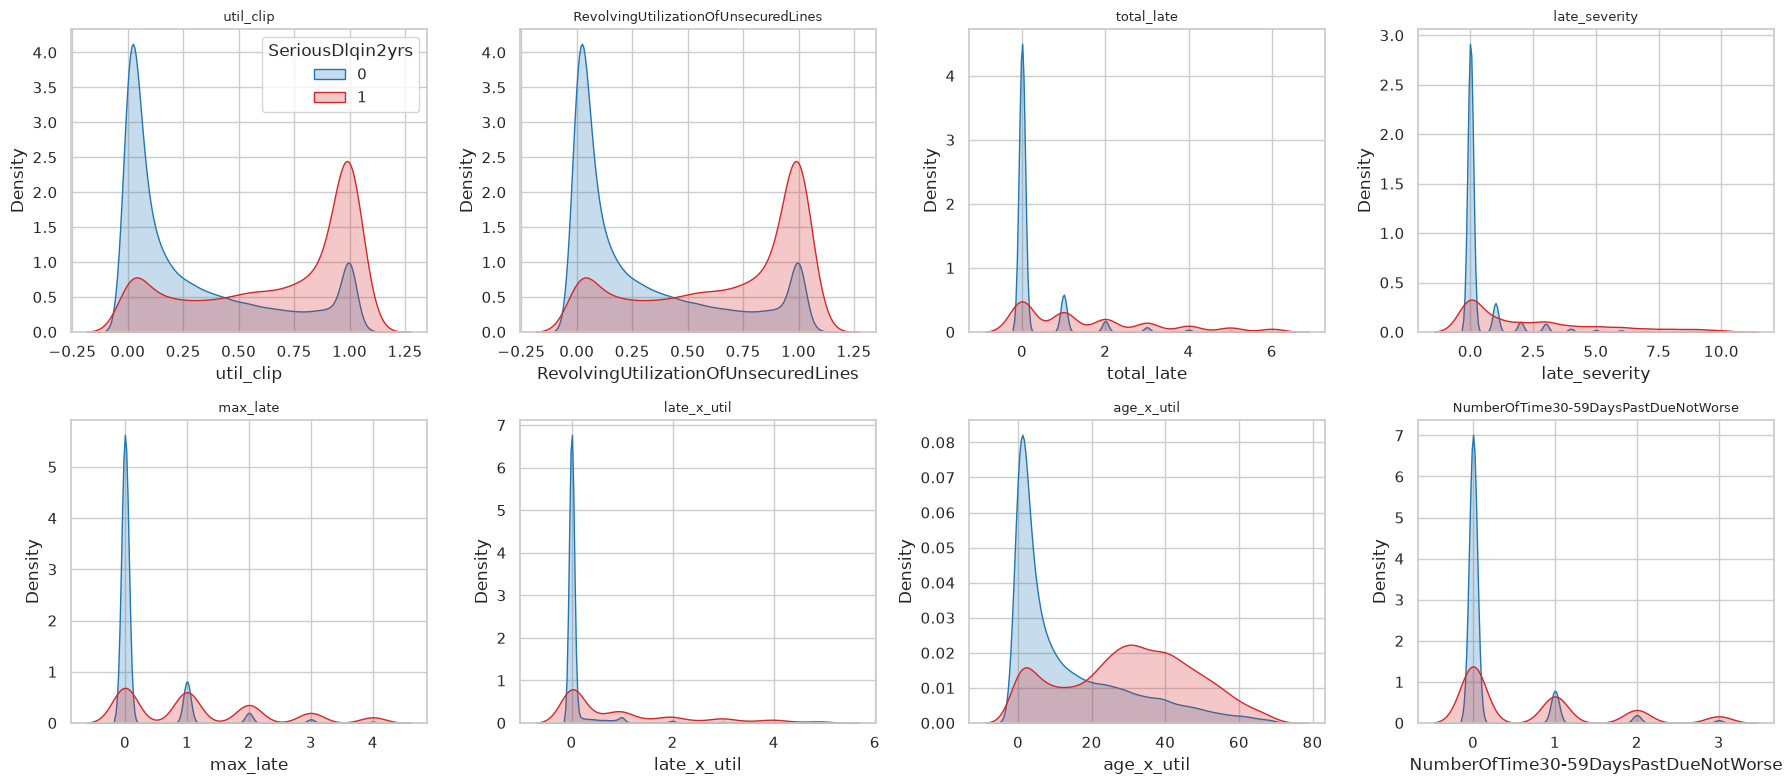

In [3]:
top = [c for c in sep["feature"] if X_fe[c].nunique() > 2][:8]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), top):
    s = X_fe[c]
    lo, hi = s.quantile([0.01, 0.99])
    for k, col in ((0, "#1f77b4"), (1, "#d62728")):
        sns.kdeplot(s[(y == k) & s.between(lo, hi)], ax=ax, color=col, fill=True,
                    alpha=0.25, common_norm=False, label=str(k))
    ax.set_title(c, fontsize=9)
axes.ravel()[0].legend(title=TARGET)
plt.tight_layout()

## 3. Separabilidad multivariada (cota con modelos) y aporte de las features
AUC en CV estratificada de 5 folds. Referencia exploratoria; la validación formal va en el notebook 03.

In [4]:
LGB = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=50,
           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42,
           verbose=-1, n_jobs=-1)
XGB = dict(n_estimators=300, learning_rate=0.05, max_depth=4, min_child_weight=5,
           subsample=0.8, colsample_bytree=0.8, tree_method="hist", eval_metric="auc",
           random_state=42, n_jobs=-1)
skf = StratifiedKFold(5, shuffle=True, random_state=42)


def cv_auc(model, X):
    p = cross_val_predict(model, X, y, cv=skf, method="predict_proba")[:, 1]
    folds = [roc_auc_score(y.iloc[va], p[va]) for _, va in skf.split(X, y)]
    return roc_auc_score(y, p), np.mean(folds), np.std(folds)


candidates = {
    "logreg · crudas": (make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                      LogisticRegression(C=0.1, max_iter=2000)), X_raw),
    "lightgbm · crudas": (lgb.LGBMClassifier(**LGB), X_raw),
    "lightgbm · features": (lgb.LGBMClassifier(**LGB), X_fe),
    "xgboost · crudas": (xgb.XGBClassifier(**XGB), X_raw),
    "xgboost · features": (xgb.XGBClassifier(**XGB), X_fe),
}
res = []
for name, (model, X) in candidates.items():
    oof, mean, std = cv_auc(model, X)
    res.append((name, oof, mean, std))
    print(f"{name:22s} OOF {oof:.5f} | folds {mean:.5f} ± {std:.5f}")
pd.DataFrame(res, columns=["modelo", "auc_oof", "auc_folds_media", "auc_folds_std"]).round(5)

logreg · crudas        OOF 0.70037 | folds 0.70040 ± 0.00329
lightgbm · crudas      OOF 0.86217 | folds 0.86230 ± 0.00795
lightgbm · features    OOF 0.86224 | folds 0.86239 ± 0.00797
xgboost · crudas       OOF 0.86427 | folds 0.86442 ± 0.00706
xgboost · features     OOF 0.86496 | folds 0.86510 ± 0.00739


,modelo,auc_oof,auc_folds_media,auc_folds_std
0,logreg · crudas,0.70037,0.70040,0.00329
1,lightgbm · crudas,0.86217,0.86230,0.00795
2,lightgbm · features,0.86224,0.86239,0.00797
3,xgboost · crudas,0.86427,0.86442,0.00706
4,xgboost · features,0.86496,0.86510,0.00739


## 4. Importancia de las variables (XGBoost, ganancia)

<Axes: title={'center': 'Importancia (gain), top 20'}>

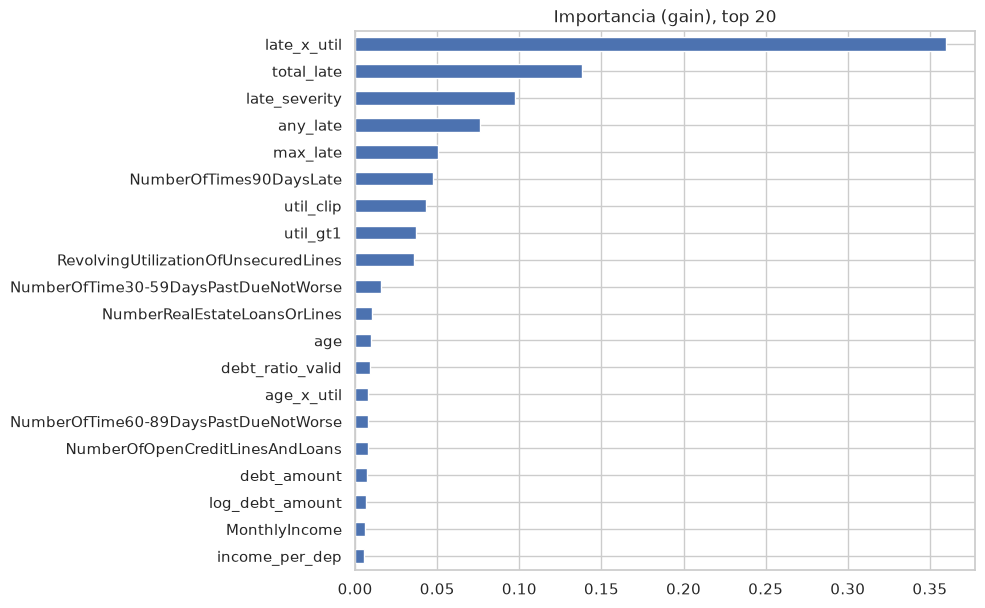

In [5]:
m = xgb.XGBClassifier(**XGB, importance_type="gain").fit(X_fe, y)
imp = pd.Series(m.feature_importances_, index=X_fe.columns).sort_values()
imp.tail(20).plot.barh(figsize=(8, 7), title="Importancia (gain), top 20")

## 5. Proyección PCA 2D (solo ilustrativa)
Una proyección lineal a 2D casi siempre muestra traslape; la separabilidad real es multivariada y no lineal.

Varianza explicada: [0.246 0.185]


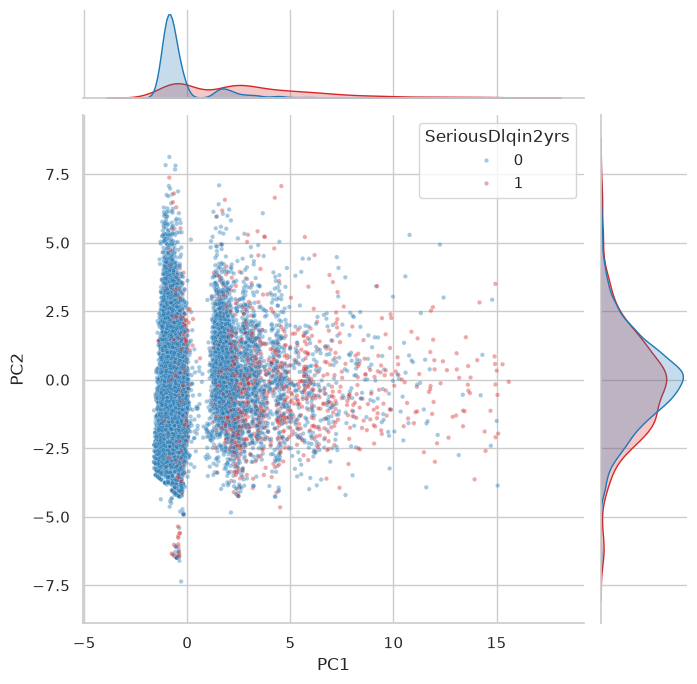

In [6]:
cols = ["util_clip", "age", "log_income", "log_debt_amount", "debt_ratio_valid", "total_late",
        "max_late", "late_severity", "any_late", "late_sentinel", "income_missing",
        "non_re_lines", "NumberOfDependents", "NumberOfOpenCreditLinesAndLoans",
        "NumberRealEstateLoansOrLines"]
Z = X_fe[cols].clip(upper=X_fe[cols].quantile(0.999), axis=1)
Z = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(Z))
pca = PCA(n_components=2, random_state=42).fit(Z)
print("Varianza explicada:", pca.explained_variance_ratio_.round(3))
P = pd.DataFrame(pca.transform(Z), columns=["PC1", "PC2"])
P[TARGET] = y.values
P = P.sample(20000, random_state=42)
sns.jointplot(data=P, x="PC1", y="PC2", hue=TARGET, palette={0: "#1f77b4", 1: "#d62728"},
              height=7, s=10, alpha=0.4, marginal_kws=dict(common_norm=False, fill=True))

## 6. Conclusiones (completar con el equipo)
- Variables univariadamente más separadoras:
- Features nuevas que aportan (comparar crudas vs features):
- Diferencia XGBoost vs LightGBM vs regresión logística:
- Hipótesis de DebtRatio/ingreso 0: confirmada o no: